<a href="https://colab.research.google.com/github/utsavmakavana455-ops/Clustering-eBay-Men-s-Fragrance-Listings/blob/main/COM7022_clustering_executed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COM7022 Machine Learning – Task 1: Clustering of eBay men's fragrance listings


In [ ]:
# 1. Setup
import re, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figs", exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f"figs/{name}.png", dpi=160); plt.show()


## 2. Data understanding

In [ ]:
raw = pd.read_csv("/content/Sales-[5444] (1).csv")
print("Shape:", raw.shape)
print("\nData types:\n", raw.dtypes)
print("\nMissing values:\n", raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())
print("\nNumeric summary:\n", raw[["price","available","sold"]].describe().round(2))
print("\nCategory spellings (raw):", raw["Catatory"].nunique())
print(raw["Catatory"].value_counts().head(8))
print("\nCountry of item location:")
print(raw["itemLocation"].str.split(",").str[-1].str.strip().value_counts().head(5))
# Consistency check: does the 'sold' column agree with the listing text?
txt_sold = raw["text"].str.extract(r"([\d,]+)\s+sold")[0].str.replace(",","").astype(float)
bad = ((txt_sold != raw["sold"]) & txt_sold.notna() & raw["sold"].notna()).sum()
print("\nRows where 'sold' column disagrees with listing text:", bad)
print(raw.loc[(txt_sold != raw["sold"]) & txt_sold.notna() & raw["sold"].notna(), ["text","sold"]])


Shape: (1000, 10)

Data types:
 Item_Name             object
details               object
Catatory              object
price                float64
priceWithCurrency     object
available            float64
text                  object
sold                 float64
lastUpdated           object
itemLocation          object
dtype: object

Missing values:
 Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64

Duplicate rows: 0

Numeric summary:
         price  available      sold
count  995.00     889.00    992.00
mean    46.43      20.05    775.25
std     35.55      61.55   3211.43
min      3.00       2.00      1.00
25%     22.99       5.00     14.00
50%     35.71      10.00     49.50
75%     59.00      10.00    324.75
max    259.09     842.00  54052.00

Category spellings (raw): 63


## 3. Cleaning

In [ ]:
df = raw.copy()

# 3.1 Units sold: the listing text is the more reliable source
df["sold_clean"] = txt_sold.fillna(df["sold"])

# 3.2 Price: recover missing values from the displayed price string; flag non-USD listings
price_str = df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0].str.replace(",","").astype(float)
df["price_clean"] = df["price"].fillna(price_str)
df["non_usd"] = df["priceWithCurrency"].fillna("").str.match(r"^(?!US)\w+ \$")
print("Prices recovered from price string:", (df["price"].isna() & price_str.notna()).sum())
print("Non-USD listings:", df["non_usd"].sum())

# 3.3 Stock level: numeric 'available', else parse the text ('Last One' = 1)
avail_txt = df["text"].str.extract(r"(\d+)\s+available")[0].astype(float)
avail_txt[df["text"].fillna("").str.contains("Last One")] = 1
df["available_clean"] = df["available"].fillna(avail_txt)
print("Stock still unknown ('Limited quantity'):", df["available_clean"].isna().sum())

# 3.4 Fragrance type: collapse 63 spellings into 4 groups
def ftype(s):
    if pd.isna(s): return "Other"
    s = s.lower()
    if "toilette" in s: return "Eau de Toilette"
    if "eau de parfum" in s or "eau de perfume" in s: return "Eau de Parfum"
    if "cologne" in s: return "Cologne"
    return "Other"
df["type"] = df["Catatory"].apply(ftype)
print("\n", df["type"].value_counts())

# 3.5 Remove rows that cannot be used
n0 = len(df)
df = df[~df["non_usd"]].dropna(subset=["price_clean","sold_clean"]).copy()
print(f"\nRows removed: {n0-len(df)}  ->  {len(df)} remain")

# Unknown stock: impute with median (documented limitation)
med_av = df["available_clean"].median()
df["available_clean"] = df["available_clean"].fillna(med_av)
df["revenue_proxy"] = df["price_clean"] * df["sold_clean"]
print("Median stock used for imputation:", med_av)


Prices recovered from price string: 5
Non-USD listings: 3
Stock still unknown ('Limited quantity'): 64

 type
Eau de Toilette    458
Eau de Parfum      314
Other              159
Cologne             69
Name: count, dtype: int64

Rows removed: 9  ->  991 remain
Median stock used for imputation: 9.0


## 4. Exploration of the cleaned data

       price_clean  sold_clean  available_clean
count       991.00      991.00           991.00
mean         46.15      768.49            18.53
std          34.83     3205.56            58.48
min           3.00        1.00             1.00
25%          22.99       14.00             4.00
50%          35.68       50.00             9.00
75%          59.00      323.00            10.00
max         259.09    54052.00           842.00

Skewness (raw):
 price_clean        1.96
sold_clean         9.77
available_clean    8.61
dtype: float64

Skewness (log1p):
 log_price        0.09
log_sold         0.53
log_available    1.58
dtype: float64
price_clean: 52 IQR outliers
sold_clean: 135 IQR outliers
available_clean: 98 IQR outliers


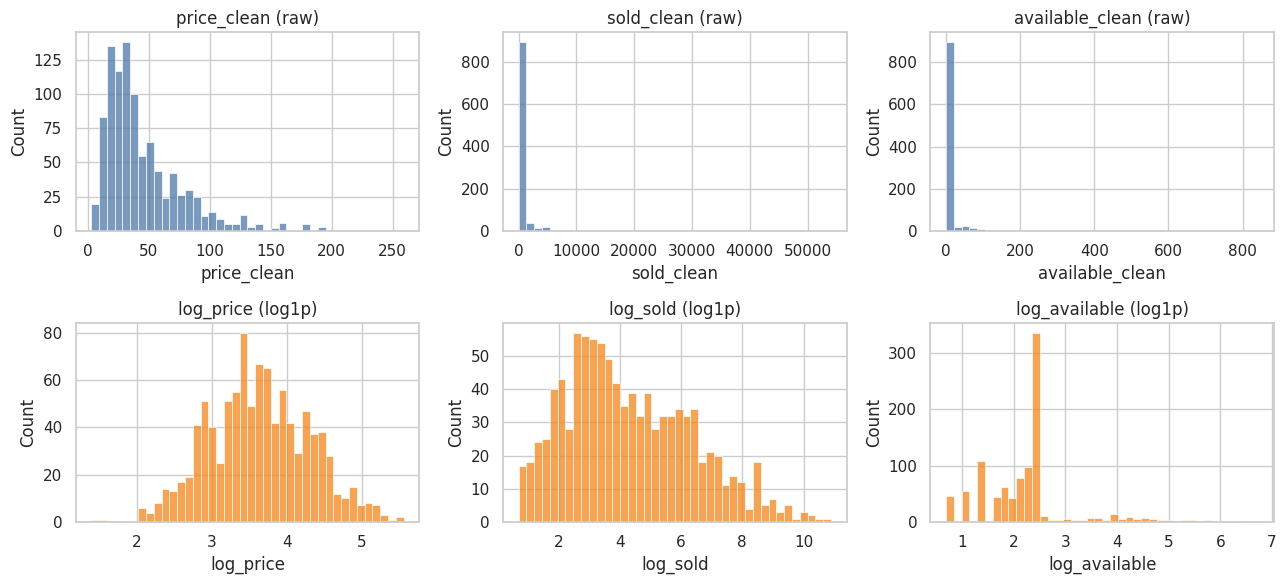

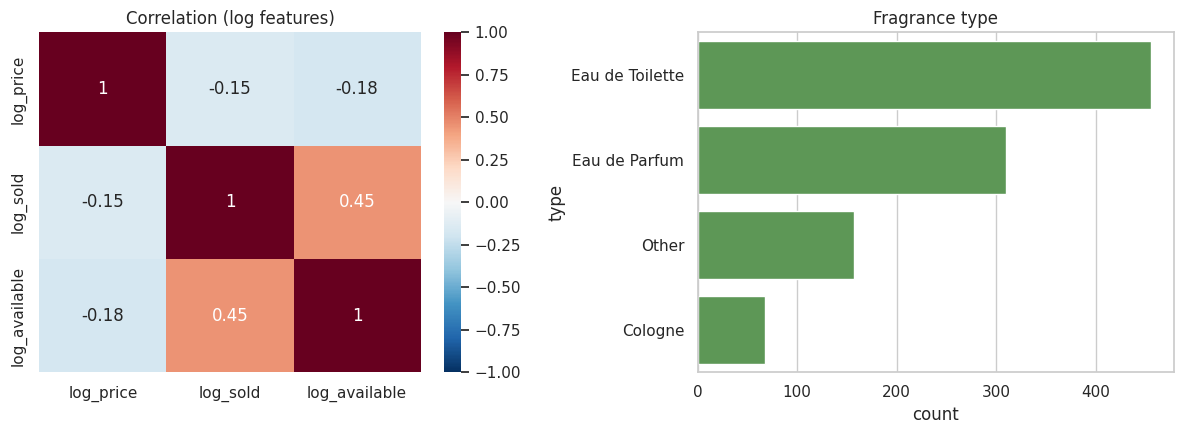

               log_price  log_sold  log_available
log_price           1.00     -0.15          -0.18
log_sold           -0.15      1.00           0.45
log_available      -0.18      0.45           1.00


In [ ]:
num = ["price_clean","sold_clean","available_clean"]
print(df[num].describe().round(2))
print("\nSkewness (raw):\n", df[num].skew().round(2))
for c in num:
    df["log_"+c.replace("_clean","")] = np.log1p(df[c])
logc = ["log_price","log_sold","log_available"]
print("\nSkewness (log1p):\n", df[logc].skew().round(2))

# IQR outliers on raw variables
for c in num:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n_out = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    print(f"{c}: {n_out} IQR outliers")

fig, ax = plt.subplots(2,3, figsize=(13,6))
for i,(c,l) in enumerate(zip(num,logc)):
    sns.histplot(df[c], bins=40, ax=ax[0,i], color="#4C78A8"); ax[0,i].set_title(f"{c} (raw)")
    sns.histplot(df[l], bins=40, ax=ax[1,i], color="#F58518"); ax[1,i].set_title(f"{l} (log1p)")
save("fig1_distributions")

fig, ax = plt.subplots(1,2, figsize=(12,4.5))
sns.heatmap(df[logc].corr(), annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Correlation (log features)")
sns.countplot(y="type", data=df, order=df["type"].value_counts().index, ax=ax[1], color="#54A24B"); ax[1].set_title("Fragrance type")
save("fig2_corr_type")
print(df[logc].corr().round(2))


## 5. Feature selection and scaling
Set A uses the three numeric behaviour variables. Set B adds one-hot fragrance type. The two are compared before one is chosen.

In [ ]:
XA_raw = df[logc].values
XA = StandardScaler().fit_transform(XA_raw)
type_d = pd.get_dummies(df["type"]).astype(float)
XB = np.hstack([XA, StandardScaler().fit_transform(type_d.values)])

def quick(X, ks=range(2,9)):
    rows=[]
    for k in ks:
        l = KMeans(k, n_init=20, random_state=SEED).fit_predict(X)
        rows.append((k, silhouette_score(X,l)))
    return pd.DataFrame(rows, columns=["k","silhouette"]).set_index("k").round(3)
cmp_feat = pd.concat([quick(XA).rename(columns={"silhouette":"A: numeric only"}),
                      quick(XB).rename(columns={"silhouette":"B: numeric + type"})], axis=1)
print(cmp_feat)
X = XA   # decision is justified by the table above and in the report
print("\nFeature matrix used:", X.shape)


   A: numeric only  B: numeric + type
k                                    
2            0.306              0.297
3            0.280              0.390
4            0.309              0.459
5            0.294              0.413
6            0.273              0.393
7            0.286              0.358
8            0.285              0.350

Feature matrix used: (991, 3)


## 6. K-Means

        WCSS  Silhouette  Davies-Bouldin  Calinski-Harabasz
k                                                          
2   2015.349       0.306           1.308            469.952
3   1529.529       0.280           1.165            466.206
4   1158.775       0.309           1.024            515.096
5    986.785       0.294           1.059            496.159
6    884.406       0.273           1.091            465.231
7    791.037       0.286           1.029            452.371
8    725.113       0.285           1.025            435.346
9    667.733       0.285           1.036            423.780
10   617.974       0.287           1.008            415.386


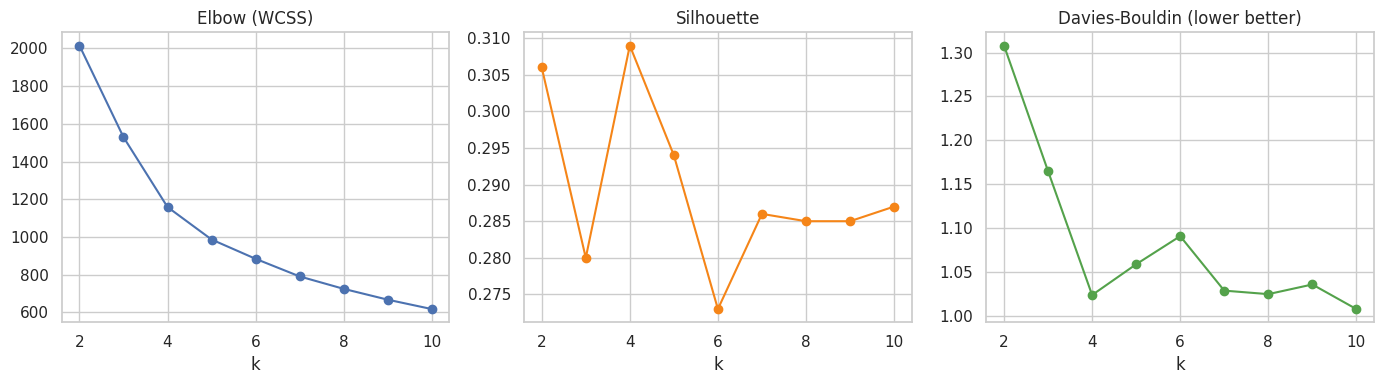

K-Means chosen k = 4 | sizes: [294 364 249  84]


In [ ]:
def metrics(X, labels):
    m = labels != -1
    if len(set(labels[m])) < 2: return (np.nan,)*3
    return (silhouette_score(X[m],labels[m]), davies_bouldin_score(X[m],labels[m]),
            calinski_harabasz_score(X[m],labels[m]))

rows=[]
for k in range(2,11):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    s,d,c = metrics(X, km.labels_)
    rows.append((k, km.inertia_, s, d, c))
km_tab = pd.DataFrame(rows, columns=["k","WCSS","Silhouette","Davies-Bouldin","Calinski-Harabasz"]).set_index("k").round(3)
print(km_tab)

fig, ax = plt.subplots(1,3, figsize=(14,4))
ax[0].plot(km_tab.index, km_tab["WCSS"], "o-"); ax[0].set_title("Elbow (WCSS)"); ax[0].set_xlabel("k")
ax[1].plot(km_tab.index, km_tab["Silhouette"], "o-", c="#F58518"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
ax[2].plot(km_tab.index, km_tab["Davies-Bouldin"], "o-", c="#54A24B"); ax[2].set_title("Davies-Bouldin (lower better)"); ax[2].set_xlabel("k")
save("fig3_kmeans_selection")

K_KM = 4
km = KMeans(K_KM, n_init=20, random_state=SEED).fit(X)
df["km"] = km.labels_
print("K-Means chosen k =", K_KM, "| sizes:", np.bincount(km.labels_))


## 7. Hierarchical clustering

linkage  average  complete   ward
k                                
2          0.383     0.430  0.440
3          0.397     0.236  0.242
4          0.363     0.192  0.268
5          0.237     0.230  0.254
6          0.148     0.217  0.239
7          0.181     0.214  0.228
8          0.179     0.209  0.231
  linkage  Silhouette  Davies-Bouldin  Calinski-Harabasz
k                                                       
2    ward       0.440           0.808            326.060
3    ward       0.242           1.357            349.728
4    ward       0.268           1.096            429.870
5    ward       0.254           1.137            422.126
6    ward       0.239           1.088            393.631
7    ward       0.228           1.075            368.882
8    ward       0.231           1.075            355.882


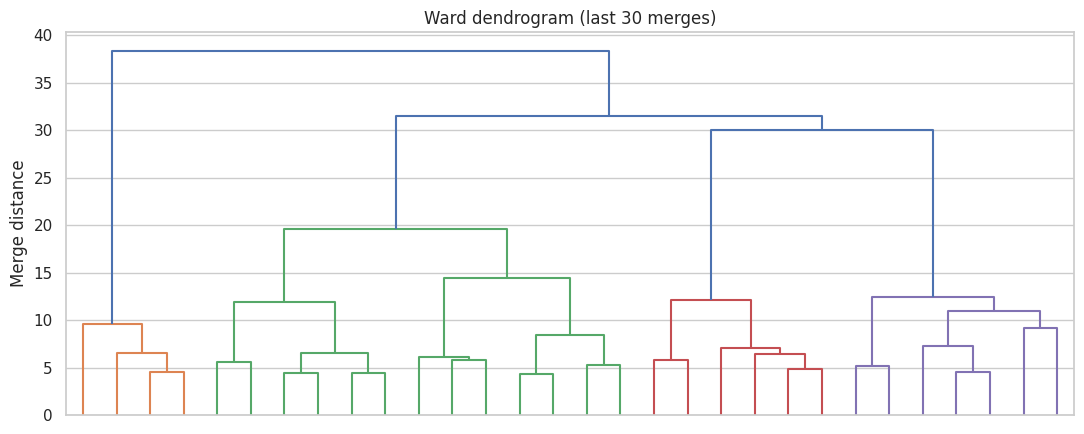

Hierarchical (Ward) k = 4 | sizes: [441 199 271  80]


In [ ]:
rows=[]
for link in ["ward","average","complete"]:
    for k in range(2,9):
        l = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        s,d,c = metrics(X,l); rows.append((link,k,s,d,c))
hc_tab = pd.DataFrame(rows, columns=["linkage","k","Silhouette","Davies-Bouldin","Calinski-Harabasz"]).round(3)
print(hc_tab.pivot(index="k", columns="linkage", values="Silhouette"))
print(hc_tab[hc_tab.linkage=="ward"].set_index("k"))

Z = linkage(X, method="ward")
plt.figure(figsize=(11,4.5))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=0.6*max(Z[:,2]))
plt.title("Ward dendrogram (last 30 merges)"); plt.ylabel("Merge distance")
save("fig4_dendrogram")

K_HC = 4
hc = AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit(X)
df["hc"] = hc.labels_
print("Hierarchical (Ward) k =", K_HC, "| sizes:", np.bincount(hc.labels_))


## 8. DBSCAN

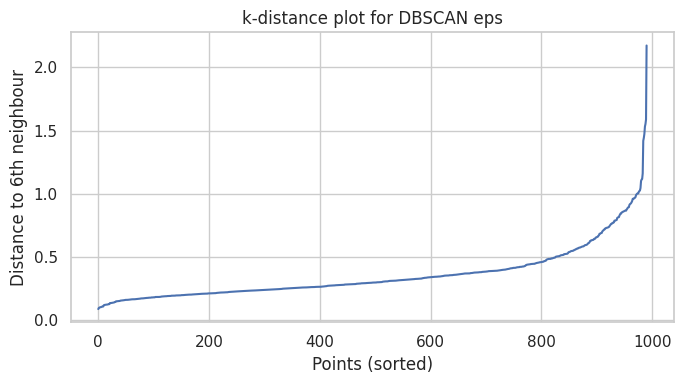

k-distance percentiles (90/95/99): [0.63 0.82 1.1 ]
 min_samples  eps  clusters  noise_%  Silhouette  Davies-Bouldin
           4  0.2        30   54.490       0.063           0.750
           4  0.3        17   25.126      -0.252           0.901
           4  0.4         7   13.320      -0.062           0.928
           4  0.5         3    7.265       0.336           0.971
           6  0.2        12   73.461       0.215           0.777
           6  0.3         6   36.932       0.049           0.873
           6  0.4         6   17.255      -0.036           0.795
           6  0.5         2    9.788       0.372           0.727
           6  0.6         2    6.256       0.398           0.750
           6  0.8         2    1.615       0.554           0.402
          10  0.2         4   93.138       0.535           0.690
          10  0.3         5   52.472      -0.014           0.839
          10  0.4         2   27.144       0.329           0.617
          10  0.5         3   14.127  

In [ ]:
dim = X.shape[1]
mins_rule = 2*dim          # common rule of thumb (2 x dimensions)
nn = NearestNeighbors(n_neighbors=mins_rule).fit(X)
kd = np.sort(nn.kneighbors(X)[0][:, -1])
plt.figure(figsize=(7,4)); plt.plot(kd); plt.xlabel("Points (sorted)"); plt.ylabel(f"Distance to {mins_rule}th neighbour")
plt.title("k-distance plot for DBSCAN eps"); save("fig5_kdistance")
print("k-distance percentiles (90/95/99):", np.percentile(kd,[90,95,99]).round(2))

rows=[]
for ms in [4,6,10,15]:
    for eps in np.arange(0.2,1.01,0.1):
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        ncl = len(set(l))-(1 if -1 in l else 0)
        s,d,c = metrics(X,l)
        rows.append((ms, round(eps,1), ncl, (l==-1).mean()*100, s, d))
db_tab = pd.DataFrame(rows, columns=["min_samples","eps","clusters","noise_%","Silhouette","Davies-Bouldin"]).round(3)
print(db_tab[db_tab.clusters>=2].to_string(index=False))

EPS, MINS = 0.6, 6
db = DBSCAN(eps=EPS, min_samples=MINS).fit(X)
df["db"] = db.labels_
print("\nDBSCAN chosen eps =", EPS, "min_samples =", MINS)
print("Cluster sizes (-1 = noise):", dict(zip(*np.unique(db.labels_, return_counts=True))))


## 9. PCA

Explained variance ratio: [0.516 0.302 0.182]
Cumulative: [0.516 0.818 1.   ]

Loadings:
                 PC1   PC2
log_price     -0.39  0.92
log_sold       0.65  0.31
log_available  0.66  0.24


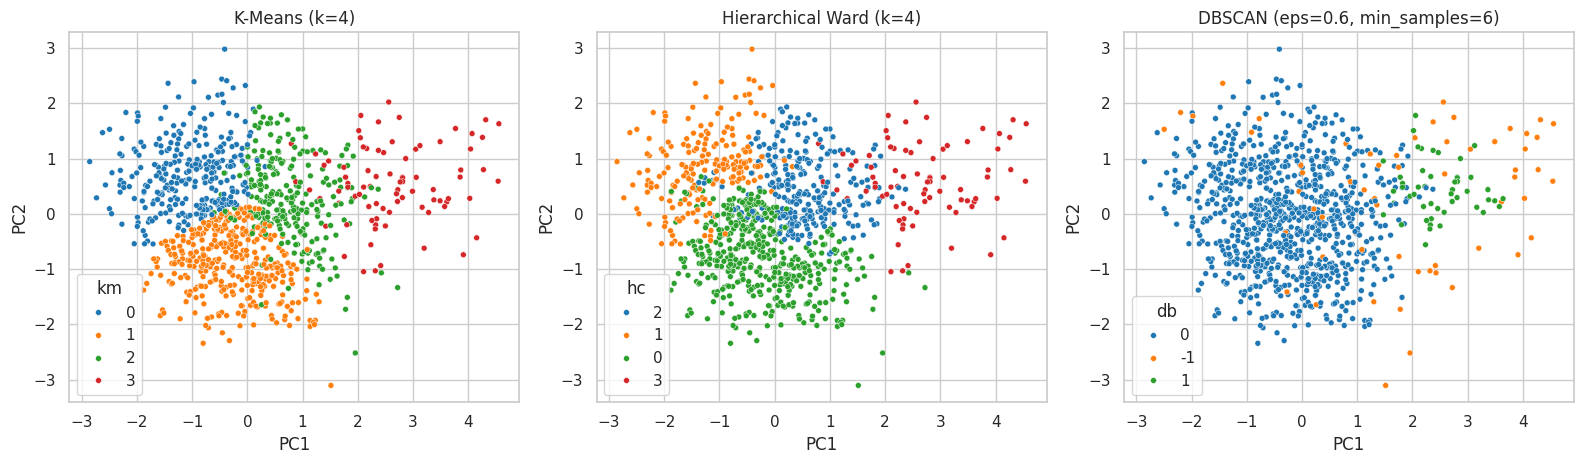

In [ ]:
pca = PCA(random_state=SEED).fit(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Cumulative:", pca.explained_variance_ratio_.cumsum().round(3))
load = pd.DataFrame(pca.components_[:2].T, index=logc, columns=["PC1","PC2"]).round(2)
print("\nLoadings:\n", load)
P = PCA(2, random_state=SEED).fit_transform(X)

fig, ax = plt.subplots(1,3, figsize=(16,4.8))
for a,col,title in zip(ax, ["km","hc","db"], [f"K-Means (k={K_KM})", f"Hierarchical Ward (k={K_HC})", f"DBSCAN (eps={EPS}, min_samples={MINS})"]):
    sns.scatterplot(x=P[:,0], y=P[:,1], hue=df[col].astype(str), palette="tab10", s=18, ax=a, legend="brief")
    a.set_title(title); a.set_xlabel("PC1"); a.set_ylabel("PC2")
save("fig6_pca_clusters")


## 10. Model comparison and stability

In [ ]:
def row(name, labels):
    s,d,c = metrics(X, labels)
    return dict(Model=name, Clusters=len(set(labels))-(1 if -1 in labels else 0),
                Noise_pct=round((labels==-1).mean()*100,1), Silhouette=round(s,3),
                DaviesBouldin=round(d,3), CalinskiHarabasz=round(c,1))
hc2 = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)
comp = pd.DataFrame([row("K-Means", df.km.values), row("Hierarchical (Ward)", df.hc.values),
                     row("Hierarchical (Ward, k=2)", hc2), row("DBSCAN", df.db.values)])
# DBSCAN noise points: how do the 'outliers' differ from the rest?
print("DBSCAN noise vs non-noise (medians):")
print(df.assign(noise=df.db==-1).groupby("noise")[["price_clean","sold_clean","available_clean"]].median().round(1))
print("DBSCAN cluster sizes:", dict(zip(*np.unique(df.db, return_counts=True))))
print(comp.to_string(index=False))

print("\nAdjusted Rand Index between models:")
print("KM vs HC :", round(adjusted_rand_score(df.km, df.hc),3))
m = df.db != -1
print("KM vs DB (non-noise):", round(adjusted_rand_score(df.km[m], df.db[m]),3))
print("HC vs DB (non-noise):", round(adjusted_rand_score(df.hc[m], df.db[m]),3))

# K-Means stability: 30 single-start runs vs the reference solution
aris=[adjusted_rand_score(km.labels_, KMeans(K_KM, n_init=1, random_state=s).fit_predict(X)) for s in range(30)]
print(f"\nK-Means stability over 30 random starts: mean ARI {np.mean(aris):.3f}, min {np.min(aris):.3f}")

# Bootstrap stability: refit on 80% subsamples, compare on the overlap
rng=np.random.RandomState(SEED); bs=[]
for _ in range(30):
    idx=rng.choice(len(X), int(.8*len(X)), replace=False)
    l=KMeans(K_KM, n_init=10, random_state=SEED).fit(X[idx]).predict(X)
    bs.append(adjusted_rand_score(km.labels_, l))
print(f"Subsample stability (80%): mean ARI {np.mean(bs):.3f}, min {np.min(bs):.3f}")


DBSCAN noise vs non-noise (medians):
       price_clean  sold_clean  available_clean
noise                                          
False         36.0        45.0              9.0
True          32.5       571.0             48.0
DBSCAN cluster sizes: {np.int64(-1): np.int64(62), np.int64(0): np.int64(880), np.int64(1): np.int64(49)}
                   Model  Clusters  Noise_pct  Silhouette  DaviesBouldin  CalinskiHarabasz
                 K-Means         4        0.0       0.309          1.024             515.1
     Hierarchical (Ward)         4        0.0       0.268          1.096             429.9
Hierarchical (Ward, k=2)         2        0.0       0.440          0.808             326.1
                  DBSCAN         2        6.3       0.398          0.750             183.8

Adjusted Rand Index between models:
KM vs HC : 0.571
KM vs DB (non-noise): 0.093
HC vs DB (non-noise): 0.101

K-Means stability over 30 random starts: mean ARI 0.969, min 0.948
Subsample stability (80%): mean 

## 11. Cluster profiles for the chosen model

      n  median_price  median_sold  median_stock  mean_sold  revenue_proxy  \
km                                                                           
0   294          74.9         21.0           6.0       48.1      1406318.4   
1   364          24.4         20.0           8.0       39.8       300575.6   
2   249          34.8        550.0          10.0     2352.3     20223943.1   
3    84          26.9        964.5          82.5     1752.8      3873815.0   

    pct_listings  pct_revenue_proxy  
km                                   
0           29.7                5.4  
1           36.7                1.2  
2           25.1               78.4  
3            8.5               15.0  

Fragrance type mix (row %):
type  Cologne  Eau de Parfum  Eau de Toilette  Other
km                                                  
0         4.0           48.0             31.0   17.0
1         8.0           29.0             40.0   23.0
2         7.0           20.0             63.0    9.0
3        

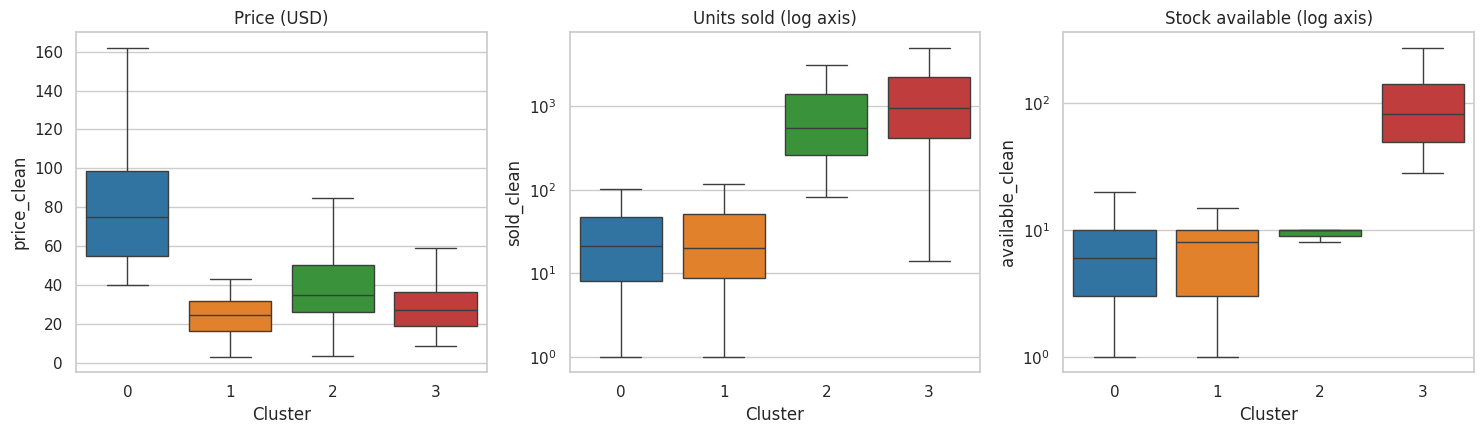

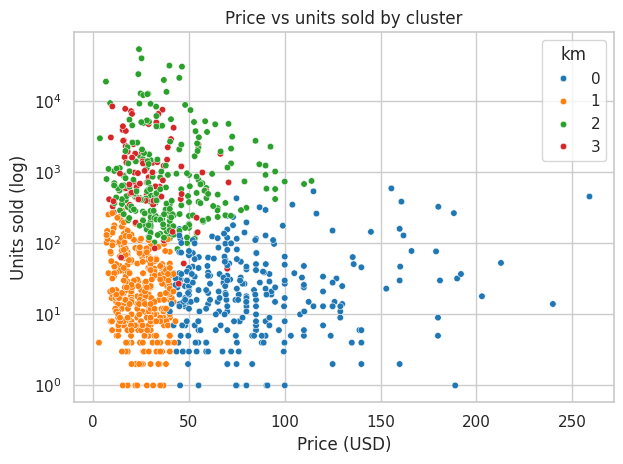

In [ ]:
FINAL = "kmeans"
col = {"kmeans":"km","hc":"hc","dbscan":"db"}[FINAL]
prof = df.groupby(col).agg(n=("price_clean","size"),
        median_price=("price_clean","median"), median_sold=("sold_clean","median"),
        median_stock=("available_clean","median"), mean_sold=("sold_clean","mean"),
        revenue_proxy=("revenue_proxy","sum")).round(1)
prof["pct_listings"] = (prof.n/prof.n.sum()*100).round(1)
prof["pct_revenue_proxy"] = (prof.revenue_proxy/prof.revenue_proxy.sum()*100).round(1)
print(prof)
print("\nFragrance type mix (row %):")
print((pd.crosstab(df[col], df["type"], normalize="index")*100).round(0))
print("\nTop brands per cluster:")
for c,g in df.groupby(col):
    print(c, g["Item_Name"].value_counts().head(4).to_dict())
print("\nNon-US share per cluster (%):")
print((df.groupby(col)["itemLocation"].apply(lambda s:(~s.str.contains("United States")).mean()*100)).round(1))

fig, ax = plt.subplots(1,3, figsize=(15,4.5))
for a,v,t in zip(ax,["price_clean","sold_clean","available_clean"],["Price (USD)","Units sold (log axis)","Stock available (log axis)"]):
    sns.boxplot(x=col, y=v, data=df, ax=a, palette="tab10", showfliers=False)
    a.set_title(t); a.set_xlabel("Cluster")
    if v!="price_clean": a.set_yscale("log")
save("fig7_profiles")

sns.scatterplot(data=df, x="price_clean", y="sold_clean", hue=col, palette="tab10", s=22)
plt.yscale("log"); plt.xlabel("Price (USD)"); plt.ylabel("Units sold (log)"); plt.title("Price vs units sold by cluster")
save("fig8_price_sold")
df.to_csv("clustered_output.csv", index=False)


## 12. Robustness check: effect of the partly imputed stock variable

In [ ]:
# 64 listings only say "Limited quantity", so their stock (median 9) is imputed.
# Check that the segments survive without relying on stock at all.
X2 = StandardScaler().fit_transform(df[["log_price","log_sold"]])
km2 = KMeans(K_KM, n_init=20, random_state=SEED).fit(X2)
print("Price + sold only: silhouette", round(silhouette_score(X2, km2.labels_),3),
      "| ARI vs main K-Means", round(adjusted_rand_score(df.km, km2.labels_),3))

# Re-fit on listings whose stock is known, then compare with the main labels
known = ~df["text"].fillna("").str.contains("Limited quantity")
Xk = StandardScaler().fit_transform(df.loc[known, logc])
kmk = KMeans(K_KM, n_init=20, random_state=SEED).fit(Xk)
print("Listings with known stock:", known.sum(),
      "| silhouette", round(silhouette_score(Xk, kmk.labels_),3),
      "| ARI vs main labels", round(adjusted_rand_score(df.loc[known,"km"], kmk.labels_),3))
print("Imputed listings per cluster:", (~known).groupby(df["km"]).sum().to_dict())


Price + sold only: silhouette 0.356 | ARI vs main K-Means 0.498
Listings with known stock: 932 | silhouette 0.307 | ARI vs main labels 0.882
Imputed listings per cluster: {0: 10, 1: 4, 2: 45, 3: 0}
